# **OPT-CVNXT-FT**

In [1]:
import os
import gc
import random
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'
import tensorflow as tf
from pathlib import Path
from PIL import Image
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from optuna.trial import TrialState
from tqdm.auto import tqdm as _tqdm
import pynvml
import time
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

In [2]:
gpus = tf.config.list_physical_devices('GPU')
if gpus:
    tf.config.set_logical_device_configuration(
        gpus[0],
        [tf.config.LogicalDeviceConfiguration(memory_limit=15360)]
    )
    print(f'GPU encontrada: {gpus[0].name} (límite 15GB)')
else:
    print('No se encontró GPU, corriendo en CPU')

GPU encontrada: /physical_device:GPU:0 (límite 15GB)


-------------
## **Búsqueda de Hiperparámetros**
---------------

In [9]:
# ── Rutas ────────────────────────────────────────────────────────────────────
REPO_ROOT      = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
DATA_PATH      = Path.home() / 'pfc' / 'Dataset ICBA Folds'
MODELS_PATH_P1 = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 1' / 'ConvNeXtTiny'
MODELS_PATH    = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo Preentrenado'
MODELS_PATH.mkdir(parents=True, exist_ok=True)

In [10]:
# ── Experimento ──────────────────────────────────────────────────────────────
EXPERIMENT_NAME = 'OPT-CVNXT-FT'
ARQUITECTURA    = 'ConvNeXtTiny'
DATASET         = 'ICBA'

# ── Imagen ───────────────────────────────────────────────────────────────────
IMG_HEIGHT  = 192
IMG_WIDTH   = 352
NUM_CLASSES = 4
CLASSES     = ['Am', 'HTA', 'EAo', 'MCH']

# ── Dataset folds ─────────────────────────────────────────────────────────────
TRAIN_FOLDS = [1, 2, 3, 4]
VAL_FOLD    = 5

# ── Entrenamiento ─────────────────────────────────────────────────────────────
LOSS_FUNCTION = 'sparse_categorical_crossentropy'
BATCH_SIZE    = 16
N_TRIALS      = 20
EPOCH_MAX     = 100
SEED          = 42
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
os.environ['PYTHONHASHSEED']         = str(SEED)
os.environ['TF_DETERMINISTIC_OPS']   = '1'
os.environ['TF_CUDNN_DETERMINISTIC'] = '1'
tf.config.experimental.enable_op_determinism()

# ── Callbacks ─────────────────────────────────────────────────────────────────
ES_PATIENCE         = 8
ES_MIN_DELTA        = 0.0001
METRIC              = 'val_loss'
DIRECTION           = 'minimize'
N_STARTUP_TRIALS    = 8
N_WARMUP_STEPS      = 10
INTERVAL_STEPS      = 1
N_MIN_TRIALS_PRUNER = 3
RLR_FACTOR          = 0.5
RLR_PATIENCE        = 5
RLR_MIN_DELTA       = 0.0001
RLR_MIN_LR          = 1e-7

# ── LP-FT ─────────────────────────────────────────────────────────────────────
WEIGHT_DECAY = 1e-2
LP_LR        = 1e-3
LP_EPOCHS    = 10

# ── Espacio de búsqueda ───────────────────────────────────────────────────────
FT_BLOCKS_OPTS   = [1, 2]
LR_FT_RANGE      = (1e-6, 1e-4)
DENSE_UNITS_OPTS = [128, 256]

In [11]:
# ── Modelo base (CVNXT-2) — referencia ───────────────────────────────────────
df_train_p1 = pd.read_csv(MODELS_PATH_P1 / 'CVNXT_training.csv')
cvnxt2_cfg  = df_train_p1[df_train_p1['run_id'] == 'CVNXT-2'].iloc[0]
CVNXT2_PATH = MODELS_PATH_P1 / 'CVNXT-2.keras'

print(f'Modelo base: CVNXT-2')
print(f'  dense_units Fase 1 : {int(cvnxt2_cfg["dense_units"])}  (referencia — en Fase 2 lo busca Optuna)')
print(f'  ft_blocks Fase 1   : {int(cvnxt2_cfg["ft_blocks"])}')
print(f'  lr_ft Fase 1       : {float(cvnxt2_cfg["learning_rate_ft"]):.2e}')
print(f'  modelo             : {CVNXT2_PATH}')
print(f'  existe             : {CVNXT2_PATH.exists()}')

Modelo base: CVNXT-2
  dense_units Fase 1 : 256  (referencia — en Fase 2 lo busca Optuna)
  ft_blocks Fase 1   : 2
  lr_ft Fase 1       : 1.38e-05
  modelo             : /home/vorsi/pfc/TESIS_bioingenieria_JonquieresOrsi/Códigos/Modelos/Fase 1/ConvNeXtTiny/CVNXT-2.keras
  existe             : True


### **Arquitectura**

Se parte del modelo **CVNXT-2** entrenado en Fase 1 sobre el dataset sintético. El backbone ConvNeXtTiny conserva los pesos aprendidos en esa fase; únicamente se reemplaza la cabeza clasificadora, que pasa de 5 clases (dataset sintético) a 4 clases patológicas del dataset ICBA (Am, HTA, EAo, MCH).

El entrenamiento sigue el mismo protocolo **LP-FT** de dos fases:
- **Fase LP** (`LP_EPOCHS` épocas): backbone congelado, solo se entrena la nueva cabeza clasificadora con `LP_LR = 1e-3` fijo.
- **Fase FT** (hasta `EPOCH_MAX` épocas con early stopping): se descongelan los últimos bloques de `stage_3` según `ft_blocks`, y se continúa con `learning_rate_ft` buscado por Optuna en [1e-6, 1e-4].

Optuna busca tres hiperparámetros: `dense_units` ∈ {128, 256}, `ft_blocks` ∈ {1, 2} y `learning_rate_ft` ∈ [1e-6, 1e-4].

In [12]:
# ── Bloques a descongelar en fase FT ─────────────────────────────────────────
FINE_TUNE_BLOCKS = {
    1: ['convnext_tiny_stage_3_block_2'],
    2: ['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2'],
}

def set_fine_tune_layers(backbone, ft_blocks):
    prefixes = [b + '_' for b in FINE_TUNE_BLOCKS[ft_blocks]]
    for layer in backbone.layers:
        layer.trainable = any(layer.name.startswith(p) for p in prefixes)

for n, prefixes in FINE_TUNE_BLOCKS.items():
    print(f'ft_blocks={n}: {prefixes}')

ft_blocks=1: ['convnext_tiny_stage_3_block_2']
ft_blocks=2: ['convnext_tiny_stage_3_block_1', 'convnext_tiny_stage_3_block_2']


In [13]:
def build_convnexttiny_ft(cvnxt2_path, dense_units, input_shape=(192, 352, 3), num_classes=4):
    p1_model = tf.keras.models.load_model(cvnxt2_path)
    base     = p1_model.get_layer('convnext_tiny')
    base.trainable = False

    inputs = tf.keras.Input(shape=input_shape)
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dense(dense_units, activation='relu')(x)
    x = layers.Dropout(0.5)(x)
    x = layers.Dense(num_classes, activation='softmax')(x)

    model = tf.keras.Model(inputs=inputs, outputs=x, name='ConvNeXtTiny_Phase2')
    del p1_model

    return model, base


### **Carga de Datos**

Dado que el dataset ICBA cuenta con aproximadamente 686 imágenes patológicas (excluyendo Normal), resulta viable cargar la totalidad de las imágenes en memoria RAM al inicio, evitando el overhead de lectura de disco por época. Las imágenes se cargan en escala de grises y se convierten a RGB replicando el canal, de forma consistente con el pipeline de Fase 1. El shuffle del conjunto de entrenamiento se realiza una única vez con semilla fija antes de comenzar el estudio Optuna, garantizando que todos los trials vean los datos en el mismo orden.

In [14]:
AUTOTUNE = tf.data.AUTOTUNE

def load_fold_images(fold_dirs, classes):
    """Carga imágenes de múltiples carpetas de fold en memoria como arrays numpy."""
    X, y = [], []
    for fold_dir in fold_dirs:
        for label_idx, cls in enumerate(classes):
            cls_dir = fold_dir / cls
            if not cls_dir.exists():
                print(f'  Advertencia: {cls_dir} no existe')
                continue
            for f in sorted(cls_dir.iterdir()):
                if f.suffix.lower() in ('.jpg', '.jpeg'):
                    img = np.array(Image.open(f).convert('L'))       # H×W grayscale
                    img = np.stack([img, img, img], axis=-1)         # H×W×3
                    X.append(img)
                    y.append(label_idx)
    return np.array(X, dtype=np.uint8), np.array(y, dtype=np.int32)

# ── Cargar datos en memoria ───────────────────────────────────────────────────
print('Cargando datos en memoria...')
train_dirs = [DATA_PATH / 'train' / f'fold {i}' for i in TRAIN_FOLDS]
val_dirs   = [DATA_PATH / 'train' / f'fold {VAL_FOLD}']

X_train, y_train = load_fold_images(train_dirs, CLASSES)
X_val,   y_val   = load_fold_images(val_dirs,   CLASSES)

# Shuffle de entrenamiento con seed fija (una sola vez antes de Optuna)
np.random.seed(SEED)
idx     = np.random.permutation(len(X_train))
X_train = X_train[idx]
y_train = y_train[idx]

print(f'\nDatos cargados:')
print(f'  X_train : {X_train.shape}   y_train : {y_train.shape}')
print(f'  X_val   : {X_val.shape}     y_val   : {y_val.shape}')
print(f'\nDistribución de clases:')
header = f"{'Clase':<8}" + f"{'train':>8}" + f"{'val':>8}"
print(header)
print('-' * len(header))
for i, cls in enumerate(CLASSES):
    print(f'{cls:<8}{(y_train == i).sum():>8}{(y_val == i).sum():>8}')
print(f"{'TOTAL':<8}{len(y_train):>8}{len(y_val):>8}")

Cargando datos en memoria...

Datos cargados:
  X_train : (442, 192, 352, 3)   y_train : (442,)
  X_val   : (107, 192, 352, 3)     y_val   : (107,)

Distribución de clases:
Clase      train     val
------------------------
Am           120      29
HTA          114      28
EAo          124      30
MCH           84      20
TOTAL        442     107


### **Estudio de Optuna**

In [15]:
class OptunaPruningCallback(tf.keras.callbacks.Callback):
    def __init__(self, trial, monitor='val_loss'):
        super().__init__()
        self.trial   = trial
        self.monitor = monitor

    def on_epoch_end(self, epoch, logs=None):
        value = logs.get(self.monitor)
        if value is not None:
            self.trial.report(value, epoch)
        if self.trial.should_prune():
            raise optuna.TrialPruned()


def objective(trial):
    tf.keras.backend.clear_session()
    gc.collect()
    random.seed(SEED)
    np.random.seed(SEED)
    tf.random.set_seed(SEED)

    # ── Hiperparámetros ────────────────────────────────────────────────────────
    dense_units = trial.suggest_categorical('dense_units',      DENSE_UNITS_OPTS)
    ft_blocks   = trial.suggest_categorical('ft_blocks',        FT_BLOCKS_OPTS)
    lr_ft       = trial.suggest_float('learning_rate_ft',       *LR_FT_RANGE, log=True)

    # ── Check anti-duplicados ─────────────────────────────────────────────────
    _existing = next(
        (t for t in trial.study.trials
         if t.state == TrialState.COMPLETE
         and t.number != trial.number
         and t.params == trial.params),
        None
    )
    if _existing is not None:
        print(f'  Trial {trial.number}: duplicado del Trial {_existing.number} → devolviendo val_loss conocido')
        return _existing.value

    # ── Datasets desde arrays en memoria ──────────────────────────────────────
    train_ds = (
        tf.data.Dataset.from_tensor_slices((X_train, y_train))
        .shuffle(len(X_train), seed=SEED, reshuffle_each_iteration=True)
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )
    val_ds = (
        tf.data.Dataset.from_tensor_slices((X_val, y_val))
        .batch(BATCH_SIZE)
        .prefetch(AUTOTUNE)
    )

    model, base = build_convnexttiny_ft(
        CVNXT2_PATH, dense_units,
        input_shape = (IMG_HEIGHT, IMG_WIDTH, 3),
        num_classes = NUM_CLASSES,
    )

    # ── Fase 1: LP — backbone congelado, solo entrena la cabeza ──────────────
    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=LP_LR, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    model.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = LP_EPOCHS,
        verbose         = 0,
    )

    # ── Fase 2: FT — descongelar bloques seleccionados ────────────────────────
    set_fine_tune_layers(base, ft_blocks)

    model.compile(
        optimizer = tf.keras.optimizers.AdamW(learning_rate=lr_ft, weight_decay=WEIGHT_DECAY),
        loss      = LOSS_FUNCTION,
        metrics   = ['accuracy'],
    )
    history = model.fit(
        train_ds,
        validation_data = val_ds,
        epochs          = EPOCH_MAX,
        callbacks       = [
            EarlyStopping(
                monitor              = METRIC,
                patience             = ES_PATIENCE,
                min_delta            = ES_MIN_DELTA,
                restore_best_weights = True,
            ),
            ReduceLROnPlateau(
                monitor   = METRIC,
                factor    = RLR_FACTOR,
                patience  = RLR_PATIENCE,
                min_delta = RLR_MIN_DELTA,
                min_lr    = RLR_MIN_LR,
            ),
            OptunaPruningCallback(trial, monitor=METRIC),
        ],
        verbose = 0,
    )

    trial.set_user_attr('epochs_trained', LP_EPOCHS + len(history.history[METRIC]))
    result = min(history.history[METRIC])

    del model, base, train_ds, val_ds, history
    gc.collect()
    tf.keras.backend.clear_session()
    gc.collect()

    return result

In [16]:
_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')

study = optuna.create_study(
    direction      = DIRECTION,
    study_name     = EXPERIMENT_NAME,
    storage        = f'sqlite:///{_db_path}',
    load_if_exists = True,
    sampler        = optuna.samplers.TPESampler(seed=SEED, n_startup_trials=N_STARTUP_TRIALS),
    pruner         = optuna.pruners.MedianPruner(
        n_startup_trials = N_STARTUP_TRIALS,
        n_warmup_steps   = N_WARMUP_STEPS,
        n_min_trials     = N_MIN_TRIALS_PRUNER,
        interval_steps   = INTERVAL_STEPS,
    ),
)

# ── Limpiar zombies ───────────────────────────────────────────────────────────
_all_trials = study.trials
_zombies = [t for t in _all_trials if t.state == TrialState.RUNNING]
if _zombies:
    for t in _zombies:
        try:
            study._storage.set_trial_state_values(t._trial_id, TrialState.FAIL, {})
        except Exception:
            pass
    _all_trials = study.trials

# ── Reintentar último trial fallido ──────────────────────────────────────────
_failed = [t for t in _all_trials if t.state == TrialState.FAIL and t.params]
if _failed:
    last_failed = max(_failed, key=lambda t: t.number)
    last_done   = max((t.number for t in _all_trials if t.state in (TrialState.COMPLETE, TrialState.PRUNED)), default=-1)
    already_completed = any(
        last_failed.params == t.params
        for t in _all_trials
        if t.state == TrialState.COMPLETE
    )
    if last_failed.number > last_done and not already_completed:
        print(f'  Trial {last_failed.number} fallido → reintento')
        study.enqueue_trial(last_failed.params)

# ── Trials restantes ──────────────────────────────────────────────────────────
n_completados = len([t for t in study.trials
                     if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
n_restantes   = max(0, N_TRIALS - n_completados)
print(f'Trials completados: {n_completados} — Trials restantes: {n_restantes}')

# ── Progress bar ──────────────────────────────────────────────────────────────
_pbar = _tqdm(total=N_TRIALS, initial=n_completados, desc='Optuna', unit='trial')

def _trial_callback(study, trial):
    n_done = len([t for t in study.trials
                  if t.state in (TrialState.COMPLETE, TrialState.PRUNED)])
    if trial.state == TrialState.COMPLETE:
        _pbar.update(1)
        best = study.best_trial
        _pbar.set_postfix({
            'mejor_trial': best.number,
            'mejor_loss':  f'{best.value:.4f}',
            'ultimo':      f'{trial.value:.4f}',
        })
        print(f'Trial {trial.number:>3} | val_loss={trial.value:.4f} | mejor={best.value:.4f} (t{best.number}) | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.PRUNED:
        _pbar.update(1)
        _pbar.set_postfix({'ultimo': 'podado'})
        print(f'Trial {trial.number:>3} | PODADO | {n_done}/{N_TRIALS}')
    elif trial.state == TrialState.FAIL:
        _pbar.set_postfix({'ultimo': 'FAILED'})
        print(f'Trial {trial.number:>3} | FAILED | {n_done}/{N_TRIALS}')

study.optimize(
    objective,
    n_trials          = n_restantes,
    show_progress_bar = False,
    gc_after_trial    = True,
    catch             = (tf.errors.ResourceExhaustedError,),
    callbacks         = [_trial_callback],
)
_pbar.close()

  Trial 17 fallido → reintento
Trials completados: 16 — Trials restantes: 4


Optuna:  80%|########  | 16/20 [00:00<?, ?trial/s]

Trial  18 | val_loss=0.6752 | mejor=0.6752 (t18) | 17/20
Trial  19 | val_loss=0.6762 | mejor=0.6752 (t18) | 18/20
Trial  20 | PODADO | 19/20
Trial  21 | val_loss=0.6758 | mejor=0.6752 (t18) | 20/20


In [17]:
# ── Cargar estudio y guardar CSV ──────────────────────────────────────────────
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)
df_study = study.trials_dataframe()
display(df_study)

df_clean = df_study[df_study['state'].isin(['COMPLETE', 'PRUNED'])].copy()
df_clean = df_clean.reset_index(drop=True)
df_clean.index = df_clean.index + 1
df_clean.index.name = 'trial'

param_cols = sorted([c for c in df_clean.columns if c.startswith('params_')])
cols_order = ['value', 'state', 'datetime_start', 'datetime_complete',
              'duration', 'user_attrs_epochs_trained'] + param_cols
df_clean = df_clean[[c for c in cols_order if c in df_clean.columns]]
df_clean = df_clean.rename(columns={
    'datetime_start':            't_start',
    'datetime_complete':         't_finish',
    'user_attrs_epochs_trained': 'epochs_trained',
    **{c: c.replace('params_', '') for c in param_cols}
})
for col in ['t_start', 't_finish']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].dt.strftime('%d/%m - %H:%M')
if 'duration' in df_clean.columns:
    df_clean['duration'] = df_clean['duration'].apply(
        lambda x: f"{int(x.total_seconds()//3600):02d}:{int((x.total_seconds()%3600)//60):02d}:{int(x.total_seconds()%60):02d}" if pd.notna(x) else ''
    )
df_clean.to_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv')
print(f'CSV guardado: {len(df_clean)} trials')

,number,value,datetime_start,datetime_complete,duration,params_dense_units,params_ft_blocks,params_learning_rate_ft,user_attrs_epochs_trained,system_attrs_fixed_params,state
0,0,0.788761,2026-07-26 22:45:13.626498,2026-07-26 22:50:53.289257,0 days 00:05:39.662759,256,1,0.000002,83.0,NaN,COMPLETE
1,1,0.690214,2026-07-26 22:50:53.793503,2026-07-26 22:52:51.639334,0 days 00:01:57.845831,128,1,0.000026,23.0,NaN,COMPLETE
2,2,0.788457,2026-07-26 22:52:52.175660,2026-07-26 22:58:02.483830,0 days 00:05:10.308170,256,1,0.000002,77.0,NaN,COMPLETE
3,3,0.786425,2026-07-26 22:58:03.054215,2026-07-26 23:02:16.418102,0 days 00:04:13.363887,256,1,0.000004,58.0,NaN,COMPLETE
4,4,0.677645,2026-07-26 23:02:17.437513,2026-07-26 23:04:49.903926,0 days 00:02:32.466413,128,2,0.000008,29.0,NaN,COMPLETE
5,5,0.677315,2026-07-26 23:04:50.657491,2026-07-26 23:11:24.497952,0 days 00:06:33.840461,128,2,0.000001,83.0,NaN,COMPLETE
6,6,0.714813,2026-07-26 23:11:25.878477,2026-07-26 23:14:01.021701,0 days 00:02:35.143224,128,2,0.000085,20.0,NaN,COMPLETE
7,7,0.677531,2026-07-26 23:14:02.045510,2026-07-26 23:16:50.088619,0 days 00:02:48.043109,128,2,0.000008,29.0,NaN,COMPLETE
8,8,NaN,2026-07-26 23:16:52.583860,2026-07-26 23:57:35.846002,0 days 00:40:43.262142,128,2,0.000001,NaN,NaN,FAIL
9,9,0.730996,2026-07-26 23:57:36.253114,2026-07-27 00:00:30.845408,0 days 00:02:54.592294,128,2,0.000001,NaN,"{'dense_units': 128, 'ft_blocks': 2, 'learning...",PRUNED


CSV guardado: 20 trials


In [ ]:
import IPython
print('Reiniciando kernel...')
IPython.Application.instance().kernel.do_shutdown(restart=True)

-------------
## **Resultados**
---------------

In [ ]:
# ── Reconstruir contexto post-restart ─────────────────────────────────────────
import subprocess
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from optuna.trial import TrialState
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

REPO_ROOT       = Path(subprocess.run(['git', 'rev-parse', '--show-toplevel'], capture_output=True, text=True).stdout.strip())
MODELS_PATH     = REPO_ROOT / 'Códigos' / 'Modelos' / 'Fase 2' / 'Modelo Preentrenado'
EXPERIMENT_NAME = 'OPT-CVNXT-FT'
DIRECTION       = 'minimize'

_db_path = MODELS_PATH / (EXPERIMENT_NAME + '.db')
study = optuna.load_study(
    study_name = EXPERIMENT_NAME,
    storage    = f'sqlite:///{_db_path}',
)

n_complete = len([t for t in study.trials if t.state == TrialState.COMPLETE])
n_pruned   = len([t for t in study.trials if t.state == TrialState.PRUNED])
print(f'Trials completos: {n_complete} | Podados: {n_pruned} | Mejor val_loss: {study.best_value:.4f} (trial {study.best_trial.number})')

### **Evolución del Estudio**

In [18]:
df_trials = pd.read_csv(MODELS_PATH / f'{EXPERIMENT_NAME}.csv', index_col='trial')

param_cols = [c for c in df_trials.columns if c not in
              ['value', 'state', 't_start', 't_finish', 'duration', 'epochs_trained']]

fmt = {'value': '{:.4f}'}
if 'learning_rate_ft' in df_trials.columns:
    fmt['learning_rate_ft'] = '{:.2e}'

display(df_trials.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
1,0.7888,COMPLETE,26/07 - 22:45,26/07 - 22:50,00:05:39,83.000000,256,1,2.05e-06
2,0.6902,COMPLETE,26/07 - 22:50,26/07 - 22:52,00:01:57,23.000000,128,1,2.61e-05
3,0.7885,COMPLETE,26/07 - 22:52,26/07 - 22:58,00:05:10,77.000000,256,1,2.31e-06
4,0.7864,COMPLETE,26/07 - 22:58,26/07 - 23:02,00:04:13,58.000000,256,1,3.82e-06
5,0.6776,COMPLETE,26/07 - 23:02,26/07 - 23:04,00:02:32,29.000000,128,2,8.17e-06
6,0.6773,COMPLETE,26/07 - 23:04,26/07 - 23:11,00:06:33,83.000000,128,2,1.24e-06
7,0.7148,COMPLETE,26/07 - 23:11,26/07 - 23:14,00:02:35,20.000000,128,2,8.54e-05
8,0.6775,COMPLETE,26/07 - 23:14,26/07 - 23:16,00:02:48,29.000000,128,2,7.59e-06
9,0.7310,PRUNED,26/07 - 23:57,27/07 - 00:00,00:02:54,-,128,2,1.04e-06


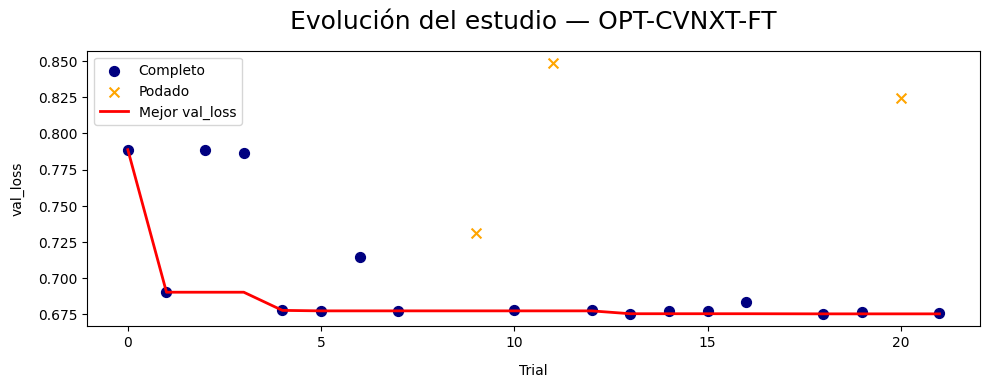

In [19]:
complete = [t for t in study.trials if t.state == TrialState.COMPLETE]
pruned   = [t for t in study.trials if t.state == TrialState.PRUNED]

fig, ax = plt.subplots(figsize=(10, 4))

if complete:
    ax.scatter([t.number for t in complete], [t.value for t in complete],
               color='navy', s=50, label='Completo')

if pruned:
    pruned_y = [list(t.intermediate_values.values())[-1] if t.intermediate_values else None
                for t in pruned]
    ax.scatter([t.number for t in pruned], pruned_y,
               color='orange', s=50, marker='x', label='Podado')

if complete:
    sorted_complete = sorted(complete, key=lambda t: t.number)
    best_so_far = pd.Series([t.value for t in sorted_complete]).cummin()
    ax.plot([t.number for t in sorted_complete], best_so_far,
            color='red', linewidth=2, label='Mejor val_loss')

ax.set_xlabel('Trial', labelpad=10)
ax.set_ylabel('val_loss', labelpad=10)
ax.set_title(f'Evolución del estudio — {EXPERIMENT_NAME}', fontsize=18, y=1.05)
ax.legend()
plt.tight_layout()
plt.show()

### **Análisis por Hiperparámetro**

In [20]:
try:
    import plotly
    fig = optuna.visualization.plot_param_importances(study)
    fig.update_traces(marker_color='navy')
    fig.update_layout(title=f'Importancia de hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado — instalar con: pip install plotly')

/tmp/ipykernel_1334713/2762354712.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(
/tmp/ipykernel_1334713/2762354712.py:18: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax_left.boxplot(


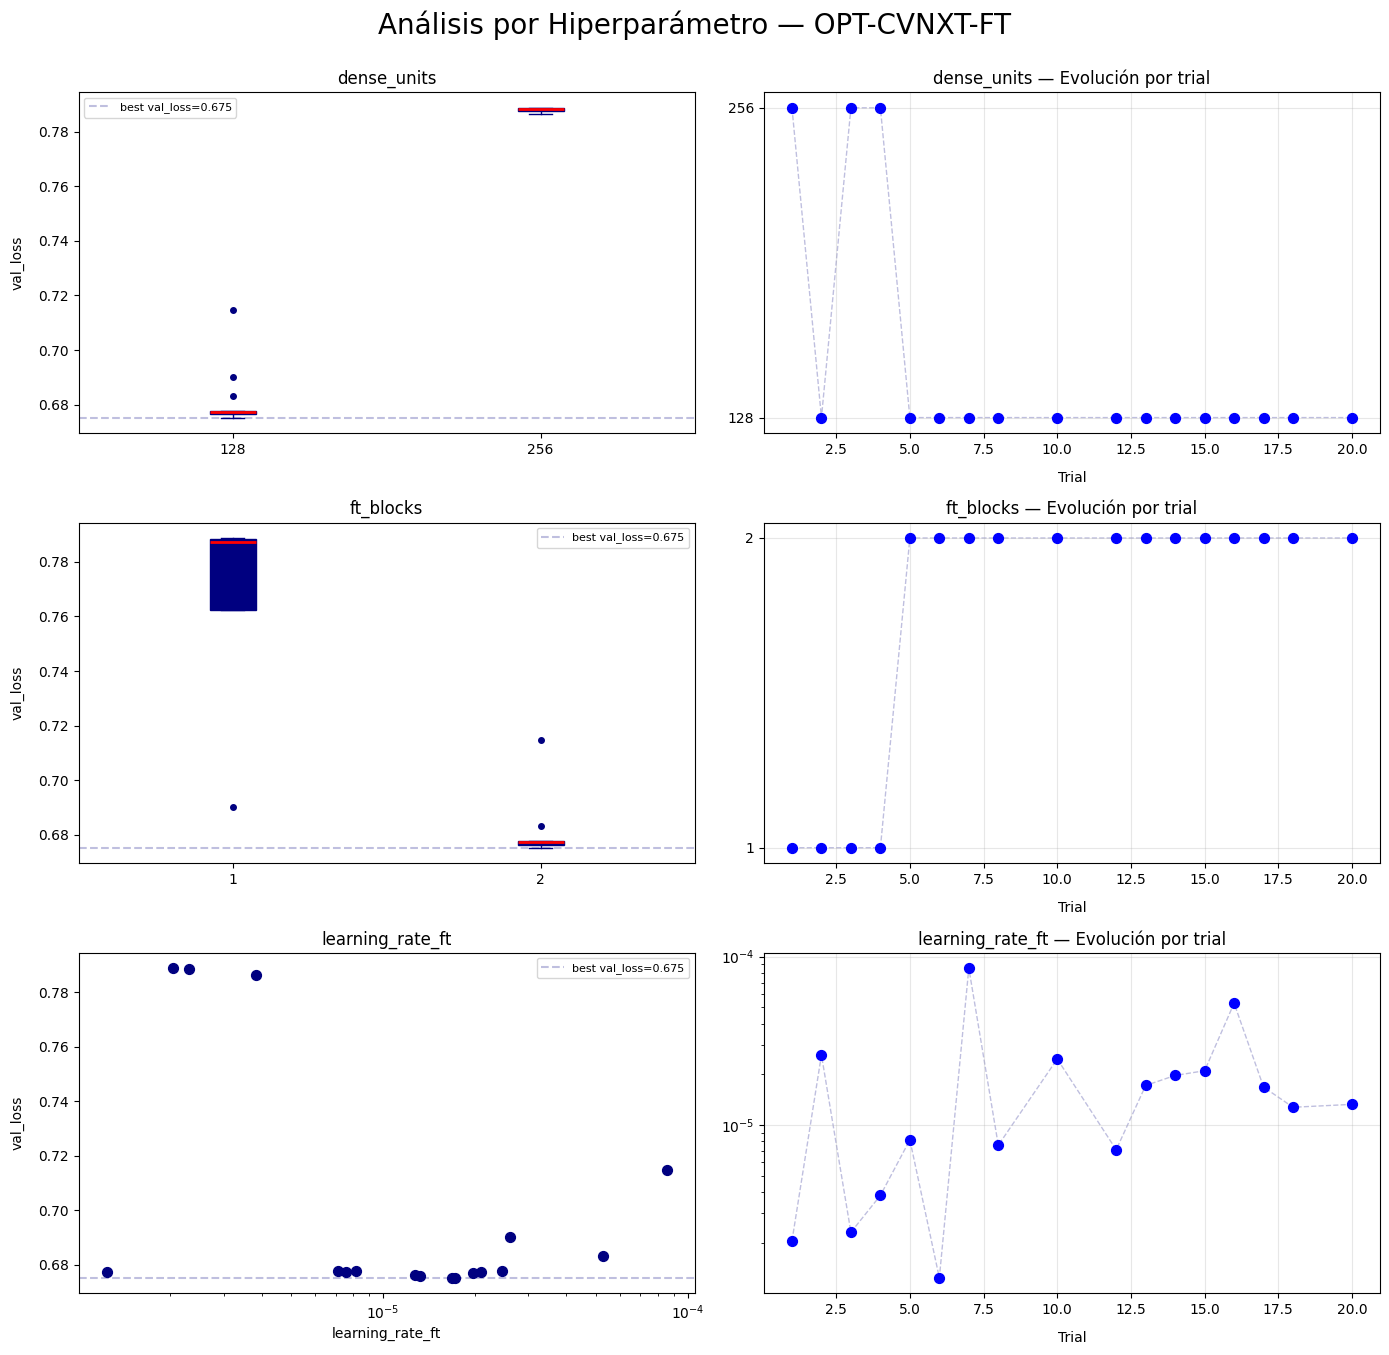

In [21]:
df_complete = df_trials[df_trials['state'] == 'COMPLETE'].copy()
df_complete['number'] = df_complete.index

n_params = len(param_cols)
fig, axes = plt.subplots(n_params, 2, figsize=(14, 4.5 * n_params))
if n_params == 1:
    axes = axes.reshape(1, 2)

for i, param in enumerate(param_cols):
    ax_left  = axes[i, 0]
    ax_right = axes[i, 1]

    is_cat = df_complete[param].dtype == object or df_complete[param].nunique() <= 4

    if is_cat:
        groups = sorted(df_complete[param].dropna().unique())
        data   = [df_complete[df_complete[param] == g]['value'].values for g in groups]
        ax_left.boxplot(
            data, labels=[str(g) for g in groups], patch_artist=True,
            boxprops    = dict(facecolor='navy', color='navy'),
            medianprops = dict(color='red', linewidth=2),
            whiskerprops= dict(color='navy'),
            capprops    = dict(color='navy'),
            flierprops  = dict(markerfacecolor='navy', markeredgecolor='navy', marker='o', markersize=4),
        )
    else:
        ax_left.scatter(df_complete[param], df_complete['value'], color='navy', s=50)
        if param == 'learning_rate_ft':
            ax_left.set_xscale('log')
        ax_left.set_xlabel(param)

    ax_left.axhline(study.best_value, color='navy', linestyle='--', alpha=0.25, linewidth=1.5,
                    label=f'best val_loss={study.best_value:.3f}')
    ax_left.set_ylabel('val_loss', labelpad=10)
    ax_left.set_title(param)
    ax_left.legend(fontsize=8)

    df_sorted = df_complete.sort_values('number')
    if is_cat:
        cats    = sorted(df_complete[param].dropna().unique())
        cat_map = {c: j for j, c in enumerate(cats)}
        y_vals  = df_sorted[param].map(cat_map)
        ax_right.plot(df_sorted['number'], y_vals, color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], y_vals, color='blue', s=50, zorder=2)
        ax_right.set_yticks(range(len(cats)))
        ax_right.set_yticklabels([str(c) for c in cats])
    else:
        ax_right.plot(df_sorted['number'], df_sorted[param], color='navy', alpha=0.25, linewidth=1, linestyle='--', zorder=1)
        ax_right.scatter(df_sorted['number'], df_sorted[param], color='blue', s=50, zorder=2)
        if param == 'learning_rate_ft':
            ax_right.set_yscale('log')

    ax_right.set_xlabel('Trial', labelpad=10)
    ax_right.set_title(f'{param} — Evolución por trial')
    ax_right.grid(True, alpha=0.3)

plt.suptitle(f'Análisis por Hiperparámetro — {EXPERIMENT_NAME}', fontsize=20, y=1)
plt.tight_layout()
plt.show()

### **Combinación de Hiperparámetros**

In [22]:
try:
    import plotly
    fig = optuna.visualization.plot_parallel_coordinate(study)
    fig.update_layout(title=f'Combinación de Hiperparámetros — {EXPERIMENT_NAME}')
    fig.show()
except ImportError:
    print('plotly no instalado')

In [23]:
df_ranked = df_trials[df_trials['state'].isin(['COMPLETE', 'PRUNED'])].sort_values('value')
display(df_ranked.style.format(fmt, na_rep='-'))

,value,state,t_start,t_finish,duration,epochs_trained,dense_units,ft_blocks,learning_rate_ft
trial,,,,,,,,,
17,0.6752,COMPLETE,27/07 - 01:37,27/07 - 01:40,00:02:52,23.000000,128,2,1.68e-05
13,0.6753,COMPLETE,27/07 - 00:07,27/07 - 00:09,00:02:03,23.000000,128,2,1.72e-05
20,0.6758,COMPLETE,27/07 - 01:44,27/07 - 01:46,00:02:12,23.000000,128,2,1.33e-05
18,0.6762,COMPLETE,27/07 - 01:40,27/07 - 01:42,00:02:10,23.000000,128,2,1.28e-05
14,0.6772,COMPLETE,27/07 - 00:09,27/07 - 00:11,00:02:02,23.000000,128,2,1.97e-05
15,0.6773,COMPLETE,27/07 - 00:11,27/07 - 00:13,00:01:59,22.000000,128,2,2.10e-05
6,0.6773,COMPLETE,26/07 - 23:04,26/07 - 23:11,00:06:33,83.000000,128,2,1.24e-06
8,0.6775,COMPLETE,26/07 - 23:14,26/07 - 23:16,00:02:48,29.000000,128,2,7.59e-06
12,0.6776,COMPLETE,27/07 - 00:04,27/07 - 00:07,00:02:30,29.000000,128,2,7.14e-06
